In [4]:
# Install required packages
!pip install --upgrade sympy --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires sympy==1.13.1; python_version >= "3.9", but you have sympy 1.14.0 which is incompatible.


In [2]:
# Install required packages
!pip install --upgrade sympy grad-cam seaborn --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 61.1 MB/s eta 0:00:00:00:010:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 54.2 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 79.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 17.3 MB/s eta 0:

In [5]:


import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
from timm import create_model
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter
import os
import random
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import gc

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define transformations
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


Using device: cuda


In [7]:
# Create balanced dataset
import os
import random
data_dir = '/kaggle/input/nct-crc-he-100k/NCT-CRC-HE-100K'
balanced_dir = '/kaggle/working/NCT_balanced'
os.makedirs(balanced_dir, exist_ok=True)
categories = ["MUC", "TUM", "DEB", "BACK", "ADI", "MUS", "NORM", "LYM", "STR"]
target_size = 5000

for cls in categories:
    src_path = os.path.join(data_dir, cls)
    dst_path = os.path.join(balanced_dir, cls)
    os.makedirs(dst_path, exist_ok=True)
    files = os.listdir(src_path)
    if len(files) > target_size:
        selected = random.sample(files, target_size)
    else:
        selected = files.copy()
        while len(selected) < target_size:
            selected.append(random.choice(files))
    for i, f in enumerate(selected):
        src_file = os.path.join(src_path, f)
        dst_file = os.path.join(dst_path, f"{i}_{f}")
        if not os.path.exists(dst_file):
            try:
                os.symlink(src_file, dst_file)
            except FileExistsError:
                pass
print("✅ Balanced dataset created with symlinks at:", balanced_dir)

✅ Balanced dataset created with symlinks at: /kaggle/working/NCT_balanced


In [8]:
# Load dataset
dataset = datasets.ImageFolder(root="/kaggle/working/NCT_balanced", transform=transform_train)

# Print dataset details
print("Classes:", dataset.classes)
print("Class-to-Index Mapping:", dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000})


In [9]:
test_dataset = datasets.ImageFolder(root="/kaggle/input/crc-val-he-7k/CRC-VAL-HE-7K", transform=transform_test)
# Print dataset details
print("Classes:", test_dataset.classes)
print("Class-to-Index Mapping:", test_dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in test_dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 1338, 8: 1233, 4: 1035, 1: 847, 6: 741, 3: 634, 5: 592, 7: 421, 2: 339})


Train Dataset Size: 31499
Validation Dataset Size: 13501
Test Dataset Size: 7180


model.safetensors:   0%|          | 0.00/13.7M [00:00<?, ?B/s]

Epoch 1/10


Validation: 100%|██████████| 422/422 [01:30<00:00,  4.66it/s]


Train Loss: 0.1606, Train Accuracy: 95.45%
Val Loss: 0.0652, Val Accuracy: 98.13%

Epoch 2/10


Validation: 100%|██████████| 422/422 [00:47<00:00,  8.89it/s]


Train Loss: 0.0488, Train Accuracy: 98.43%
Val Loss: 0.1094, Val Accuracy: 96.53%

Epoch 3/10


Validation: 100%|██████████| 422/422 [00:32<00:00, 12.97it/s]


Train Loss: 0.0312, Train Accuracy: 99.00%
Val Loss: 0.0782, Val Accuracy: 97.60%

Epoch 4/10


Validation: 100%|██████████| 422/422 [00:32<00:00, 13.15it/s]


Train Loss: 0.0224, Train Accuracy: 99.29%
Val Loss: 0.2200, Val Accuracy: 94.22%

Early stopping triggered. Stopping training.


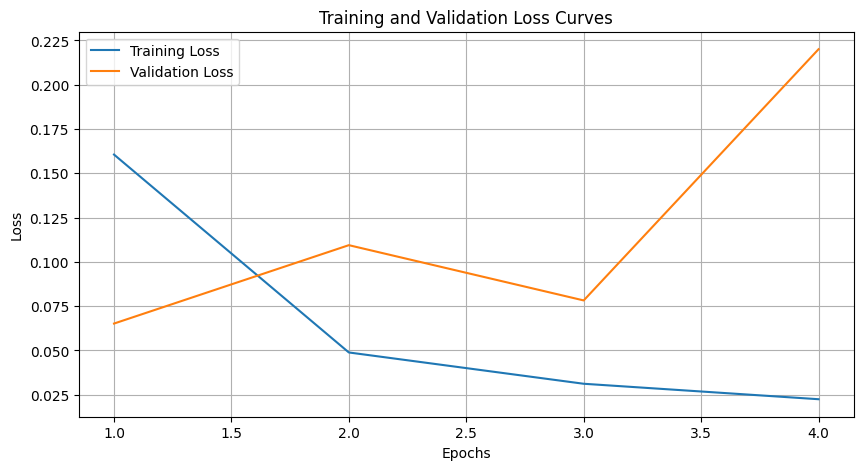

In [10]:
import timm
# Dataset split
total_size = len(dataset)
train_size = int(0.7 * total_size)
#val_size = int(0.3 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Apply test transformations
val_dataset.dataset.transform = transform_test
#test_dataset.dataset.transform = transform_test

# Verify split sizes
print("Train Dataset Size:", len(train_dataset))
print("Validation Dataset Size:", len(val_dataset))
print("Test Dataset Size:", len(test_dataset))

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Load EfficientViT model
class CustomEfficientViTB0(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        # Load EfficientViT-B0 backbone
        self.backbone = timm.create_model('efficientvit_b0.r224_in1k', pretrained=pretrained)
        # Remove its default classification head
        in_features = self.backbone.get_classifier().in_features
        self.backbone.reset_classifier(0)
        
        # Add custom classifier layers
        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    
    def forward(self, x):
        features = self.backbone(x)  # shape: [B, in_features]
        return self.classifier(features)
        
num_classes = len(dataset.classes)
model = CustomEfficientViTB0(num_classes=num_classes).to(device)
model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Training and validation
num_epochs = 10
train_losses, val_losses = [], []

# Early stopping
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

early_stopping = EarlyStopping(patience=3)

# Training loop
for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    train_correct = 0

    print(f"Epoch {epoch + 1}/{num_epochs}")
    for inputs, labels in tqdm(train_loader, desc="Training"):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()

    train_loss = running_train_loss / len(train_loader.dataset)
    train_acc = 100.0 * train_correct / len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    with torch.no_grad():
        for inputs, labels in tqdm(val_loader, desc="Validation"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = 100.0 * val_correct / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.2f}%\n")

    # Early stopping
    early_stopping(val_loss)
    if early_stopping.early_stop:
        print("Early stopping triggered. Stopping training.")
        break

# Plot loss curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()


In [13]:
# Test model with enhanced evaluation metrics
def evaluate_model(model, test_loader, class_names):
    model.eval()
    correct = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Testing"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    accuracy = 100.0 * correct / len(test_loader.dataset)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')
    
    print(f"Test Accuracy: {accuracy:.2f}%")
    print(f"Precision (weighted): {precision:.4f}")
    print(f"Recall (weighted): {recall:.4f}")
    print(f"F1-Score (weighted): {f1:.4f}")
    
    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.savefig('/kaggle/working/confusion_matrix.png', format='png', dpi=300, bbox_inches='tight')
    plt.close()
    print("Confusion Matrix saved to /kaggle/working/confusion_matrix.png")
    
    return accuracy, precision, recall, f1, cm

# Evaluate on test set
class_names = dataset.classes
accuracy, precision, recall, f1, cm = evaluate_model(model, test_loader, class_names)

Testing: 100%|██████████| 225/225 [00:46<00:00,  4.80it/s]


Test Accuracy: 90.65%
Precision (weighted): 0.9138
Recall (weighted): 0.9065
F1-Score (weighted): 0.9017
Confusion Matrix saved to /kaggle/working/confusion_matrix.png


In [14]:
# Grad-CAM implementation
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError as e:
    print(f"Error importing pytorch_grad_cam: {e}")
    print("Ensure 'grad-cam' is installed correctly with: !pip install grad-cam")
    raise

# Model wrapper for Grad-CAM
class EfficientViTModelWrapper(nn.Module):
    def __init__(self, model):
        super(EfficientViTModelWrapper, self).__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)

# Data transform for Grad-CAM
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def denormalize(tensor):
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    tensor = tensor.cpu().numpy().transpose((1, 2, 0))
    tensor = std * tensor + mean
    tensor = np.clip(tensor, 0, 1)
    return tensor

# Helper function to find the last convolutional layer
def find_last_conv_layer(model):
    def is_conv_layer(module):
        return isinstance(module, nn.Conv2d)
    
    last_conv = None
    for name, module in model.backbone.named_modules():
        if is_conv_layer(module):
            last_conv = module
            last_conv_name = name
    return last_conv, last_conv_name

# Target layer for Grad-CAM
try:
    target_layer, target_layer_name = find_last_conv_layer(model)
    if target_layer is None:
        print("No convolutional layer found in the model. Inspecting model architecture...")
        print(model.backbone)
        raise AttributeError("Could not find a valid convolutional layer for Grad-CAM.")
    print(f"Selected target layer for Grad-CAM: {target_layer_name}")
except AttributeError as e:
    print(f"Error selecting target layer: {e}")
    print("Please inspect the model architecture and specify the correct convolutional layer.")
    raise

def visualize_gradcam(image_path, model, target_layer, target_class):
    wrapper = EfficientViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer])
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = data_transform(image).unsqueeze(0).to(device)
    targets = [ClassifierOutputTarget(target_class)]
    
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    input_image = denormalize(input_tensor[0])
    visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
    
    class_name = [k for k, v in dataset.class_to_idx.items() if v == target_class][0]
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(input_image)
    plt.title(f"Original Image (Class: {class_name})")
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title("Grad-CAM")
    plt.axis('off')
    output_path = f'/kaggle/working/gradcam_{os.path.basename(image_path)}.png'
    plt.savefig(output_path, format='png', dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Grad-CAM plot saved to {output_path}")
    
    # Clean up
    del input_tensor, grayscale_cam, visualization
    torch.cuda.empty_cache()
    gc.collect()

def generate_gradcam_per_label(model, dataloader, target_layer, class_to_idx):
    wrapper = EfficientViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer])
    
    correct_samples = {label: None for label in class_to_idx.values()}
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(inputs.size(0)):
                label = labels[i].item()
                if preds[i].item() == label and correct_samples[label] is None:
                    correct_samples[label] = (inputs[i].unsqueeze(0), label)
            if all(v is not None for v in correct_samples.values()):
                break
    
    for label, sample in correct_samples.items():
        if sample is None:
            class_name = [k for k, v in class_to_idx.items() if v == label][0]
            print(f"No correct predictions found for class {class_name}. Skipping Grad-CAM.")
            continue
        input_tensor, label_idx = sample
        targets = [ClassifierOutputTarget(label_idx)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        
        input_image = denormalize(input_tensor[0])
        visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
        
        class_name = [k for k, v in class_to_idx.items() if v == label_idx][0]
        plt.figure(figsize=(8, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(input_image)
        plt.title(f"Original Image (Class: {class_name})")
        plt.axis('off')
        plt.subplot(1, 2, 2)
        plt.imshow(visualization)
        plt.title(f"Grad-CAM for {class_name}")
        plt.axis('off')
        output_path = f'/kaggle/working/gradcam_label_{class_name}.png'
        plt.savefig(output_path, format='png', dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Grad-CAM for label {class_name} saved to {output_path}")
        
        # Clean up
        del input_tensor, grayscale_cam, visualization
        torch.cuda.empty_cache()
        gc.collect()


Selected target layer for Grad-CAM: head.in_conv.conv


In [15]:
# Generate Grad-CAM visualizations
sample_image_path = test_dataset.samples[0][0]
sample_class = test_dataset.samples[0][1]
visualize_gradcam(sample_image_path, model, target_layer, sample_class)
generate_gradcam_per_label(model, test_loader, target_layer, dataset.class_to_idx)

Grad-CAM plot saved to /kaggle/working/gradcam_ADI-TCGA-AAICEQFN.tif.png
Grad-CAM for label ADI saved to /kaggle/working/gradcam_label_ADI.png
Grad-CAM for label BACK saved to /kaggle/working/gradcam_label_BACK.png
Grad-CAM for label DEB saved to /kaggle/working/gradcam_label_DEB.png
Grad-CAM for label LYM saved to /kaggle/working/gradcam_label_LYM.png
Grad-CAM for label MUC saved to /kaggle/working/gradcam_label_MUC.png
Grad-CAM for label MUS saved to /kaggle/working/gradcam_label_MUS.png
Grad-CAM for label NORM saved to /kaggle/working/gradcam_label_NORM.png
Grad-CAM for label STR saved to /kaggle/working/gradcam_label_STR.png
Grad-CAM for label TUM saved to /kaggle/working/gradcam_label_TUM.png
